<a href="https://colab.research.google.com/github/Desire-in-tech/music-genre-classification/blob/task-06%2Fmusic-genre-classification/notebooks/task_06_music_genre_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 6 — Music Genre Classification

**Goal:** classify GTZAN recordings into music genres and compare (1) track-level Librosa tabular features with Scikit-learn and (2) complete-track log-Mel spectrograms with a CNN.

This notebook is designed for Google Colab. Run top-to-bottom. Exact byte-identical copies are deduplicated before splitting; identical audio carrying conflicting genre labels is quarantined. Both approaches use the same stratified recording-level split, and no exact recording content is shared across splits.

## 1. Runtime setup

The notebook clones the project working branch, installs its package and dependencies, and records the runtime. For the CNN, select **Runtime → Change runtime type → T4 GPU** if available. The tabular experiment can run on CPU.

In [1]:
import os, sys, json, random, platform, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Desire-in-tech/music-genre-classification.git"
BRANCH = "task-06/music-genre-classification"
PROJECT_DIR = Path("/content/music-genre-classification")

if not (PROJECT_DIR / ".git").exists():
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(PROJECT_DIR)], check=True)
else:
    # Refresh an existing Colab clone so the package code always matches this notebook's branch.
    subprocess.run(["git", "-C", str(PROJECT_DIR), "fetch", "origin", BRANCH], check=True)
    subprocess.run(["git", "-C", str(PROJECT_DIR), "checkout", BRANCH], check=True)
    subprocess.run(["git", "-C", str(PROJECT_DIR), "reset", "--hard", f"origin/{BRANCH}"], check=True)

%cd /content/music-genre-classification
%pip -q install -r requirements.txt
%pip -q install -e . kagglehub tqdm

sys.path.insert(0, str(PROJECT_DIR / "src"))

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
import numpy as np
np.random.seed(SEED)

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("GPU devices:", subprocess.run(["bash", "-lc", "nvidia-smi"], capture_output=True, text=True).stdout[:1200] or "No NVIDIA GPU detected")


/content/music-genre-classification
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for music-genre-classification (pyproject.toml) ... done
Python: 3.13.16
NumPy: 2.4.6
GPU devices: Wed Nov 18 12:14:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+==========

## 2. Download and locate GTZAN

The recommended Kaggle collection is downloaded with KaggleHub. If Kaggle requires authentication, create a Kaggle API token in your Kaggle account, upload `kaggle.json` when prompted, and authenticate in the next cell. Do not commit the token.

In [2]:
from pathlib import Path
import sys
import os

# Be robust if this section is rerun after a Colab runtime restart.
PROJECT_DIR = Path("/content/music-genre-classification")
PACKAGE_SRC = PROJECT_DIR / "src"
if not (PACKAGE_SRC / "music_genre_classification" / "__init__.py").exists():
    raise FileNotFoundError(
        f"Project package not found at {PACKAGE_SRC}. Run Section 1 first to clone and install the project."
    )
sys.path.insert(0, str(PACKAGE_SRC))

import kagglehub
from music_genre_classification.data import discover_tracks

try:
    DATA_ROOT = Path(kagglehub.dataset_download("carlthome/gtzan-genre-collection"))
    print("Dataset downloaded to:", DATA_ROOT)
except Exception as exc:
    print("KaggleHub download did not complete:", repr(exc))
    print("If authentication is required, upload kaggle.json from your Kaggle account.")
    from google.colab import files
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise RuntimeError("Please upload your Kaggle API token file named kaggle.json.") from exc
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(exist_ok=True)
    token_path = kaggle_dir / "kaggle.json"
    token_path.write_bytes(uploaded["kaggle.json"])
    token_path.chmod(0o600)
    DATA_ROOT = Path(kagglehub.dataset_download("carlthome/gtzan-genre-collection"))

# To make discover_tracks work flawlessly, create a symlink named 'genres_original'
# inside a local data folder pointing to the downloaded 'genres' folder.
local_data_dir = PROJECT_DIR / "data"
local_data_dir.mkdir(exist_ok=True)
symlink_target = local_data_dir / "genres_original"
if symlink_target.is_symlink() or symlink_target.exists():
    symlink_target.unlink()

# Determine actual source genres folder path
actual_genres_path = DATA_ROOT / "genres"
if not actual_genres_path.exists():
    # Fallback to recursively locating the 'genres' folder
    for root, dirs, _ in os.walk(DATA_ROOT):
        if "genres" in dirs:
            actual_genres_path = Path(root) / "genres"
            break

symlink_target.symlink_to(actual_genres_path, target_is_directory=True)
os.environ["MUSIC_DATA_DIR"] = str(local_data_dir)

tracks = discover_tracks(local_data_dir)
print("Discovered recordings:", len(tracks))
print("Genres:", sorted(tracks.genre.unique()))
display(tracks.groupby("genre").size().rename("recordings").to_frame())
display(tracks.head())

Using Colab cache for faster access to the 'gtzan-genre-collection' dataset.
Dataset downloaded to: /kaggle/input/gtzan-genre-collection
Discovered recordings: 1000
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


,recordings
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


,track_id,path,genre
0,blues/blues.00000.au,/content/music-genre-classification/data/genre...,blues
1,blues/blues.00001.au,/content/music-genre-classification/data/genre...,blues
2,blues/blues.00002.au,/content/music-genre-classification/data/genre...,blues
3,blues/blues.00003.au,/content/music-genre-classification/data/genre...,blues
4,blues/blues.00004.au,/content/music-genre-classification/data/genre...,blues


## 3. Dataset quality audit

Inspect duration, sample rate, channels, unreadable files and exact byte-level duplicates. Exact duplicates with one consistent label are represented once; identical audio carrying conflicting genre labels is excluded from supervised training and documented. SHA-256 does not detect near-duplicates, alternate encodings, or artist overlap.

In [3]:
from music_genre_classification.data import audit_tracks, prepare_modeling_tracks

audit, exact_duplicates = audit_tracks(tracks, hash_files=True)
display(audit.groupby("genre").agg(
    recordings=("track_id", "count"),
    readable=("readable", "sum"),
    median_duration_s=("duration_seconds", "median"),
    sample_rates=("sample_rate", lambda x: ", ".join(map(str, sorted(x.dropna().unique())))),
    channel_counts=("channels", lambda x: ", ".join(map(str, sorted(x.dropna().unique())))),
))
print("Unreadable recordings:", int((~audit.readable).sum()))
print("Recordings participating in exact-duplicate groups:", len(exact_duplicates))
if len(exact_duplicates):
    display(exact_duplicates[["track_id", "genre", "sha256"]])
if (~audit.readable).any():
    display(audit.loc[~audit.readable, ["track_id", "path", "error"]])
    raise RuntimeError("Resolve unreadable audio files before training; do not silently drop them.")

model_tracks, duplicate_resolution = prepare_modeling_tracks(tracks, audit)
if len(duplicate_resolution):
    display(duplicate_resolution.drop(columns=["sha256"]))
print("Original recordings:", len(tracks))
print("Retained unique recordings:", len(model_tracks))
print("Same-label duplicate copies removed:", int(
    duplicate_resolution.loc[
        duplicate_resolution.action == "kept_first_removed_exact_copies",
        "recordings_in_group"
    ].sum() - (duplicate_resolution.action == "kept_first_removed_exact_copies").sum()
) if len(duplicate_resolution) else 0)
print("Conflicting-label recordings quarantined:", int(
    duplicate_resolution.loc[
        duplicate_resolution.action == "excluded_conflicting_labels", "recordings_in_group"
    ].sum()
) if len(duplicate_resolution) else 0)
# All downstream feature extraction and modeling use only this cleaned, unique-content frame.
tracks = model_tracks
print("Modeling genre counts:")
display(tracks.groupby("genre").size().rename("recordings").to_frame())

,recordings,readable,median_duration_s,sample_rates,channel_counts
genre,,,,,
blues,100,100,30.013333,22050,1
classical,100,100,30.013333,22050,1
country,100,100,30.013333,22050,1
disco,100,100,30.000181,22050,1
hiphop,100,100,30.013333,22050,1
jazz,100,100,30.013333,22050,1
metal,100,100,30.000181,22050,1
pop,100,100,30.000181,22050,1
reggae,100,100,30.000181,22050,1


Unreadable recordings: 0
Recordings participating in exact-duplicate groups: 14


,track_id,genre,sha256
767,pop/pop.00067.au,pop,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
771,pop/pop.00071.au,pop,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
754,pop/pop.00054.au,pop,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
760,pop/pop.00060.au,pop,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
398,disco/disco.00098.au,disco,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
399,disco/disco.00099.au,disco,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
881,reggae/reggae.00081.au,reggae,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
882,reggae/reggae.00082.au,reggae,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
658,metal/metal.00058.au,metal,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...
916,rock/rock.00016.au,rock,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...


,track_ids,genres,recordings_in_group,action
0,"[pop/pop.00067.au, pop/pop.00071.au]",[pop],2,kept_first_removed_exact_copies
1,"[pop/pop.00054.au, pop/pop.00060.au]",[pop],2,kept_first_removed_exact_copies
2,"[disco/disco.00098.au, disco/disco.00099.au]",[disco],2,kept_first_removed_exact_copies
3,"[reggae/reggae.00081.au, reggae/reggae.00082.au]",[reggae],2,kept_first_removed_exact_copies
4,"[metal/metal.00058.au, rock/rock.00016.au]","[metal, rock]",2,excluded_conflicting_labels
5,"[hiphop/hiphop.00076.au, hiphop/hiphop.00078.au]",[hiphop],2,kept_first_removed_exact_copies
6,"[metal/metal.00034.au, metal/metal.00094.au]",[metal],2,kept_first_removed_exact_copies


Original recordings: 1000
Retained unique recordings: 992
Same-label duplicate copies removed: 6
Conflicting-label recordings quarantined: 2
Modeling genre counts:


,recordings
genre,
blues,100
classical,100
country,100
disco,99
hiphop,99
jazz,100
metal,98
pop,98
reggae,99


In [4]:
import ast

with open('/content/music-genre-classification/src/music_genre_classification/data.py', 'r') as f:
    tree = ast.parse(f.read())

functions = [node.name for node in ast.walk(tree) if isinstance(node, ast.FunctionDef)]
print("Functions found in data.py:", functions)

Functions found in data.py: ['_find_audio_root', 'discover_tracks', 'sha256_file', 'audit_tracks', 'prepare_modeling_tracks', 'split_tracks']


In [5]:
with open('/content/music-genre-classification/src/music_genre_classification/data.py', 'r') as f:
    print(f.read())

"""Dataset discovery, auditing and duplicate-safe recording-level splits."""
from __future__ import annotations

import hashlib
import os
from pathlib import Path

import pandas as pd
import soundfile as sf
from sklearn.model_selection import train_test_split

AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".au"}


def _find_audio_root(root: Path) -> Path:
    if root.name == "genres_original" and root.is_dir():
        return root
    candidates = [root / "genres_original", root / "Data" / "genres_original", root / "GTZAN" / "genres_original"]
    candidates += sorted(root.glob("**/genres_original"))
    for candidate in candidates:
        if candidate.is_dir() and any(path.is_dir() for path in candidate.iterdir()):
            return candidate
    raise FileNotFoundError(
        f"Could not locate a genres_original directory under {root}. "
        "Set MUSIC_DATA_DIR to the extracted GTZAN folder."
    )


def discover_tracks(dataset_root: str | Path | None = None) -> pd.Dat

## 4. Fixed recording-level train/validation/test split

Split only after exact-content duplicate resolution. Every retained track has unique audio bytes, and the same stratified recording-level manifest is used for both representations. The test set remains untouched during model selection.

In [6]:
from music_genre_classification.data import split_tracks

train_tracks, val_tracks, test_tracks = split_tracks(
    tracks, test_size=0.20, validation_size=0.20, random_seed=SEED
)
split_frames = {"train":train_tracks,"validation":val_tracks,"test":test_tracks}
split_ids = {name:set(frame.track_id) for name,frame in split_frames.items()}
assert not (split_ids["train"] & split_ids["validation"])
assert not (split_ids["train"] & split_ids["test"])
assert not (split_ids["validation"] & split_ids["test"])
assert set.union(*split_ids.values()) == set(tracks.track_id)
for name, frame in split_frames.items():
    print(f"{name}: {len(frame)} recordings")
    display(frame.groupby("genre").size().rename("count").to_frame())
Path("artifacts").mkdir(exist_ok=True)
pd.concat([frame.assign(split=name) for name,frame in split_frames.items()]).to_csv("artifacts/split_manifest.csv",index=False)


train: 634 recordings


,count
genre,
blues,64
classical,64
country,64
disco,63
hiphop,63
jazz,64
metal,63
pop,63
reggae,63


validation: 159 recordings


,count
genre,
blues,16
classical,16
country,16
disco,16
hiphop,16
jazz,16
metal,15
pop,16
reggae,16


test: 199 recordings


,count
genre,
blues,20
classical,20
country,20
disco,20
hiphop,20
jazz,20
metal,20
pop,19
reggae,20


## 5. Tabular feature extraction

Extract one feature vector per complete recording: MFCCs, chroma, spectral centroid/bandwidth/rolloff, zero-crossing rate, RMS energy and tempo. This step is the most time-consuming part of the tabular pipeline, so its Parquet cache is reused on subsequent runs when its track IDs match the current dataset.

In [7]:
from music_genre_classification.features import extract_track_features, save_feature_table

FEATURE_CACHE = Path("cache/gtzan_track_features.parquet")
FEATURE_CACHE.parent.mkdir(exist_ok=True)
expected_ids = set(tracks.track_id)
feature_table = None
if FEATURE_CACHE.exists():
    cached = pd.read_parquet(FEATURE_CACHE)
    cached_ids = set(cached.track_id)
    # The tabular representation is unchanged, so a prior superset cache can be safely filtered.
    if expected_ids.issubset(cached_ids):
        feature_table = cached.loc[cached.track_id.isin(expected_ids)].copy()
        feature_table = feature_table.set_index("track_id").loc[tracks.track_id].reset_index()
        print("Reused and filtered cached features:", feature_table.shape)
    else:
        print("Feature cache does not cover the cleaned dataset; rebuilding.")

if feature_table is None:
    feature_rows = []
    for record in tqdm(tracks.itertuples(index=False), total=len(tracks), desc="Extracting track features"):
        values = extract_track_features(record.path, sample_rate=22050, n_mfcc=20, duration=30)
        feature_rows.append({"track_id": record.track_id, "genre": record.genre, **values})
    feature_table = pd.DataFrame(feature_rows)
    save_feature_table(feature_table, FEATURE_CACHE)

assert feature_table.track_id.is_unique
assert set(feature_table.track_id) == expected_ids
print("Feature matrix:", feature_table.shape)
display(feature_table.head())


Reused and filtered cached features: (992, 77)
Feature matrix: (992, 77)


,track_id,genre,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,tempo
0,blues/blues.00000.au,blues,-113.619382,50.703183,121.553028,17.196640,-19.151055,15.348610,42.345765,12.281505,...,360.194166,2002.657106,292.966459,3806.418650,949.383832,0.083066,0.027690,0.130192,0.053201,123.046875
1,blues/blues.00001.au,blues,-207.581535,88.151987,123.997146,23.667763,8.939120,23.931154,35.870755,16.274377,...,613.197888,2038.612143,462.482296,3548.986873,1725.338349,0.056044,0.038059,0.095892,0.048724,67.999589
2,blues/blues.00002.au,blues,-90.776346,57.617653,140.448613,22.563513,-29.100558,20.297464,31.687340,12.006151,...,395.649207,1747.382028,275.954142,3041.089944,884.842654,0.076301,0.031738,0.175494,0.052465,161.499023
3,blues/blues.00003.au,blues,-199.462007,74.134827,150.094738,21.367421,5.649169,16.032693,26.870145,12.577671,...,429.542379,1596.244204,408.212651,2185.061787,1222.372310,0.033309,0.020569,0.141139,0.079623,63.024009
4,blues/blues.00004.au,blues,-160.291856,72.098162,126.195766,29.218795,-35.602496,18.267781,22.151165,13.916657,...,585.947299,1748.367477,297.422362,3581.003346,1253.847208,0.101500,0.044199,0.091540,0.048011,135.999178


## 6. Train and select tabular baselines

Compare RBF-SVM, Random Forest and Extra Trees. Imputation and scaling (where applicable) are fitted inside each Scikit-learn pipeline using training data only. Select by validation macro-F1; only the selected model is then refitted on train + validation and evaluated on the test recordings.

In [8]:
from music_genre_classification.models import build_baseline_models
from sklearn.metrics import f1_score
from music_genre_classification.evaluation import evaluate_predictions
import joblib

indexed_features = feature_table.set_index("track_id")
def split_xy(frame):
    ordered = indexed_features.loc[frame.track_id]
    X = ordered.drop(columns=["genre"])
    y = ordered.genre.to_numpy()
    return X,y

X_train,y_train = split_xy(train_tracks)
X_val,y_val = split_xy(val_tracks)
X_test,y_test = split_xy(test_tracks)

validation_rows = []
fitted_candidates = {}
for model_name, estimator in build_baseline_models(random_seed=SEED).items():
    estimator.fit(X_train,y_train)
    val_pred = estimator.predict(X_val)
    score = f1_score(y_val,val_pred,average="macro")
    validation_rows.append({"model":model_name,"validation_macro_f1":score})
    fitted_candidates[model_name] = estimator
tabular_selection = pd.DataFrame(validation_rows).sort_values("validation_macro_f1",ascending=False)
display(tabular_selection)
best_tabular_name = tabular_selection.iloc[0].model
print("Selected tabular model:",best_tabular_name)

X_trainval = pd.concat([X_train,X_val])
y_trainval = np.concatenate([y_train,y_val])
best_tabular = build_baseline_models(random_seed=SEED)[best_tabular_name]
best_tabular.fit(X_trainval,y_trainval)
tabular_test_pred = best_tabular.predict(X_test)
genre_labels = sorted(tracks.genre.unique())
tabular_metrics = evaluate_predictions(y_test,tabular_test_pred,genre_labels)
print("Tabular test accuracy:",round(tabular_metrics["accuracy"],4))
print("Tabular test macro-F1:",round(tabular_metrics["macro_f1"],4))
joblib.dump(best_tabular,"artifacts/best_tabular_model.joblib")


,model,validation_macro_f1
2,extra_trees,0.686768
0,svm_rbf,0.678030
1,random_forest,0.665885


Selected tabular model: extra_trees
Tabular test accuracy: 0.7286
Tabular test macro-F1: 0.7236


['artifacts/best_tabular_model.joblib']

## 7. Build complete-track log-Mel spectrograms

Each recording becomes one fixed-size 128 × 256 log-Mel image, clipped to −80–0 dB and scaled to [0, 1]. The cache version is bumped so images created by the previous negative-only normalization cannot be reused. The split is created before selecting images, and no exact duplicate audio remains.

In [9]:
from music_genre_classification.features import extract_log_mel

# v2 invalidates the earlier [-1, 0] representation cache.
MEL_CACHE = Path("cache/gtzan_logmel_v2.npz")
mel_images = None
if MEL_CACHE.exists():
    archive = np.load(MEL_CACHE, allow_pickle=False)
    cached_ids = archive["track_ids"].astype(str)
    if set(cached_ids) == expected_ids and len(cached_ids) == len(tracks):
        mel_images = archive["images"]
        mel_track_ids = cached_ids
        print("Loaded normalized spectrogram cache:", mel_images.shape)
    else:
        print("Spectrogram cache does not match cleaned dataset; rebuilding.")
        MEL_CACHE.unlink()

if mel_images is None:
    mel_images = np.stack([
        extract_log_mel(
            path, sample_rate=22050, n_mels=128, hop_length=1024,
            duration=30, target_frames=256
        )
        for path in tqdm(tracks.path, desc="Creating normalized log-Mel images")
    ])
    mel_track_ids = tracks.track_id.to_numpy(dtype=str)
    np.savez_compressed(MEL_CACHE, images=mel_images, track_ids=mel_track_ids)

print("Spectrogram tensor:", mel_images.shape, mel_images.dtype)
print("Spectrogram value range:", float(mel_images.min()), "to", float(mel_images.max()))
assert mel_images.shape == (len(tracks), 128, 256, 1)
assert np.isfinite(mel_images).all()
assert mel_images.min() >= 0.0 and mel_images.max() <= 1.0
assert len(mel_track_ids) == len(tracks)


Loaded normalized spectrogram cache: (992, 128, 256, 1)
Spectrogram tensor: (992, 128, 256, 1) float32
Spectrogram value range: 0.0 to 1.0


## 8. Train the log-Mel spectrogram CNN

The previous compact, strongly regularized network failed to generalize and collapsed to one predicted class. This revision increases feature capacity, uses milder train-only augmentation and moderate dropout, and combines global average and max pooling. Early stopping and learning-rate reduction monitor validation loss only. The held-out test split is not used for architecture selection.

In [10]:
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from music_genre_classification.models import build_spectrogram_cnn

tf.keras.utils.set_random_seed(SEED)
id_to_row = {track_id: i for i, track_id in enumerate(mel_track_ids)}

def mel_xy(frame):
    indices = np.array([id_to_row[track_id] for track_id in frame.track_id])
    return mel_images[indices], frame.genre.to_numpy()

X_mel_train, y_mel_train = mel_xy(train_tracks)
X_mel_val, y_mel_val = mel_xy(val_tracks)
X_mel_test, y_mel_test = mel_xy(test_tracks)
label_encoder = LabelEncoder().fit(tracks.genre)
y_mel_train_enc = label_encoder.transform(y_mel_train)
y_mel_val_enc = label_encoder.transform(y_mel_val)
y_mel_test_enc = label_encoder.transform(y_mel_test)

print("CNN input range:", float(X_mel_train.min()), "to", float(X_mel_train.max()))
print("CNN split shapes:", X_mel_train.shape, X_mel_val.shape, X_mel_test.shape)
print("Label index mapping:", dict(enumerate(label_encoder.classes_)))
print("Training label counts:", pd.Series(y_mel_train).value_counts().sort_index().to_dict())

# Guard against a silent mismatch between split labels and encoded targets.
assert X_mel_train.shape[0] == len(y_mel_train_enc)
assert X_mel_val.shape[0] == len(y_mel_val_enc)
assert X_mel_test.shape[0] == len(y_mel_test_enc)
assert set(np.unique(y_mel_train_enc)) == set(range(len(label_encoder.classes_)))

cnn = build_spectrogram_cnn(
    X_mel_train.shape[1:], len(label_encoder.classes_), random_seed=SEED
)
cnn.summary()
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True, min_delta=1e-3
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5
    ),
]
history = cnn.fit(
    X_mel_train, y_mel_train_enc,
    validation_data=(X_mel_val, y_mel_val_enc),
    epochs=50, batch_size=16, callbacks=callbacks, verbose=1,
)

# Inspect prediction diversity on training and unseen validation data.
train_probe = cnn.predict(X_mel_train, verbose=0).argmax(axis=1)
val_probe = cnn.predict(X_mel_val, verbose=0).argmax(axis=1)
print("Training prediction counts:", pd.Series(
    label_encoder.inverse_transform(train_probe)
).value_counts().to_dict())
print("Validation prediction counts:", pd.Series(
    label_encoder.inverse_transform(val_probe)
).value_counts().to_dict())
print("Best validation accuracy:", round(max(history.history["val_accuracy"]), 4))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))

CNN input range: 0.0 to 1.0
CNN split shapes: (634, 128, 256, 1) (159, 128, 256, 1) (199, 128, 256, 1)
Label index mapping: {0: 'blues', 1: 'classical', 2: 'country', 3: 'disco', 4: 'hiphop', 5: 'jazz', 6: 'metal', 7: 'pop', 8: 'reggae', 9: 'rock'}
Training label counts: {'blues': 64, 'classical': 64, 'country': 64, 'disco': 63, 'hiphop': 63, 'jazz': 64, 'metal': 63, 'pop': 63, 'reggae': 63, 'rock': 63}


Model: "logmel_genre_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ log_mel_input       │ (None, 128, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spec_shift          │ (None, 128, 256,  │          0 │ log_mel_input[0]… │
│ (RandomTranslation) │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spec_noise          │ (None, 128, 256,  │          0 │ spec_shift[0][0]  │
│ (GaussianNoise)     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_1 (Conv2D)     │ (None, 128, 256,  │        288 │ spec_noise[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_1                │ (None, 128, 256,  │        128 │ conv_1[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_1 (Activation) │ (None, 128, 256,  │          0 │ bn_1[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_1              │ (None, 64, 128,   │          0 │ relu_1[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 128,   │          0 │ pool_1[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_2 (Conv2D)     │ (None, 64, 128,   │     18,432 │ dropout_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_2                │ (None, 64, 128,   │        256 │ conv_2[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_2 (Activation) │ (None, 64, 128,   │          0 │ bn_2[0][0]        │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_2              │ (None, 32, 64,    │          0 │ relu_2[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 64,    │          0 │ pool_2[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_3 (Conv2D)     │ (None, 32, 64,    │     73,728 │ dropout_2[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_3                │ (None, 32, 64,    │        512 │ conv_3[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_3 (Activation) │ (None, 32, 64,    │          0 │ bn_3[0][0]        │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_3              │ (None, 16, 32,    │          0 │ relu_3[0][0]    

 Total params: 127,530 (498.16 KB)

 Trainable params: 127,082 (496.41 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.1514 - loss: 3.3984 - val_accuracy: 0.1321 - val_loss: 2.4077 - learning_rate: 0.0010
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.2066 - loss: 2.1630 - val_accuracy: 0.0943 - val_loss: 2.3316 - learning_rate: 0.0010
Epoch 3/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.2729 - loss: 2.0599 - val_accuracy: 0.0943 - val_loss: 2.3138 - learning_rate: 0.0010
Epoch 4/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.2918 - loss: 1.9745 - val_accuracy: 0.1384 - val_loss: 2.2504 - learning_rate: 0.0010
Epoch 5/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.3044 - loss: 1.9566 - val_accuracy: 0.1509 - val_loss: 2.1941 - learning_rate: 0.0010
Epoch 6/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.2950 - loss: 1.8877 - val_accuracy: 0.1887 - val_loss: 2.1352 - learning_rate: 0.0010
Epoch 7/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.2997 - loss: 1.8427 - val_ac

## 9. Evaluate CNN on the held-out test recordings

The test set is used only now, after training and validation-based early stopping. Both model families are evaluated against the same ordered test tracks and genre labels.

In [11]:
cnn_probabilities = cnn.predict(X_mel_test, verbose=0)
cnn_test_pred = label_encoder.inverse_transform(cnn_probabilities.argmax(axis=1))
cnn_metrics = evaluate_predictions(y_mel_test, cnn_test_pred, genre_labels)
print("CNN test accuracy:", round(cnn_metrics["accuracy"], 4))
print("CNN test macro-F1:", round(cnn_metrics["macro_f1"], 4))
print("CNN predicted genre counts:")
display(pd.Series(cnn_test_pred).value_counts().reindex(genre_labels, fill_value=0).rename("predictions").to_frame())
print("CNN mean class probabilities:")
display(pd.Series(cnn_probabilities.mean(axis=0), index=label_encoder.classes_).sort_values(ascending=False).to_frame("mean_probability"))
cnn.save("artifacts/logmel_cnn.keras")

CNN test accuracy: 0.6482
CNN test macro-F1: 0.6362
CNN predicted genre counts:


,predictions
blues,19
classical,21
country,35
disco,13
hiphop,12
jazz,23
metal,16
pop,25
reggae,25
rock,10


CNN mean class probabilities:


,mean_probability
jazz,0.135697
country,0.119880
reggae,0.117839
classical,0.114167
pop,0.095709
disco,0.093565
rock,0.090478
blues,0.087958
hiphop,0.076075
metal,0.068633


## 10. Compare models and inspect errors

The table compares test-set metrics for the selected tabular baseline and CNN. Review per-genre scores and confusion matrices rather than relying on accuracy alone. GTZAN is small and has known quality/duplication concerns; this benchmark does not establish generalisation to arbitrary modern music.

,approach,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall
0,Tabular (extra_trees),0.728643,0.723579,0.724965,0.728947
1,Log-Mel CNN,0.648241,0.636197,0.661395,0.648421


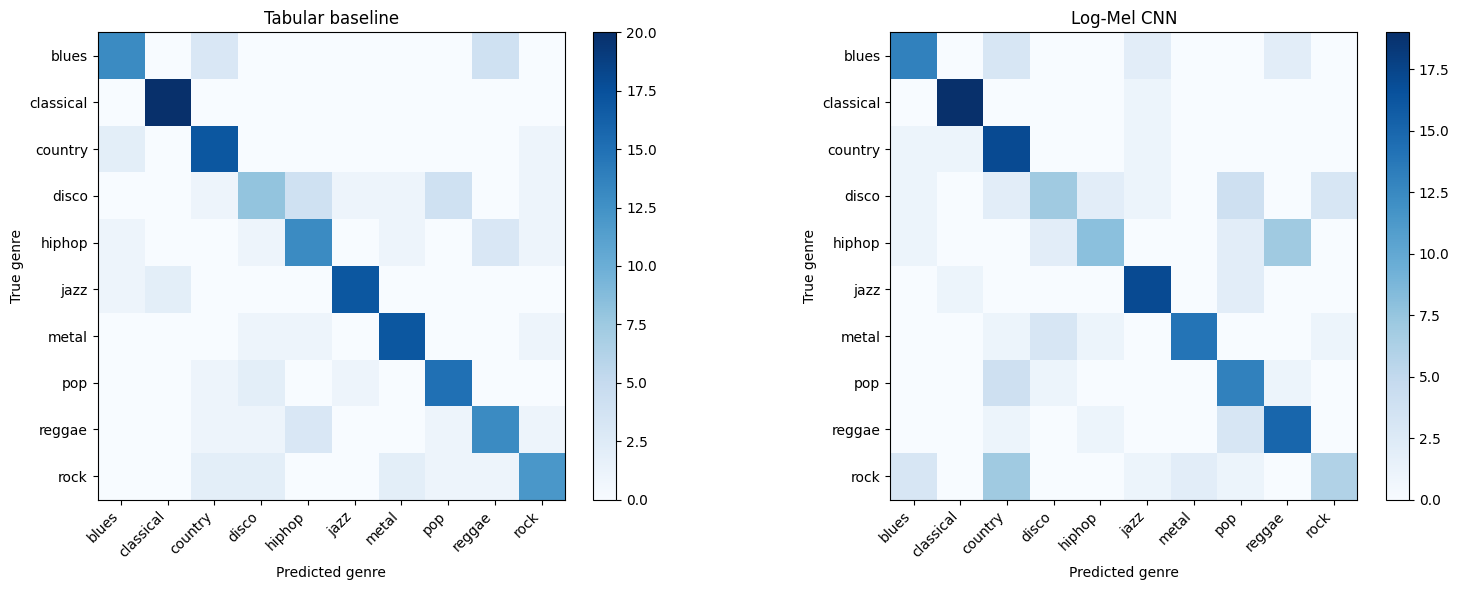

,precision,recall,f1-score,support
blues,0.764706,0.650000,0.702703,20.000000
classical,0.909091,1.000000,0.952381,20.000000
country,0.680000,0.850000,0.755556,20.000000
disco,0.533333,0.400000,0.457143,20.000000
hiphop,0.619048,0.650000,0.634146,20.000000
jazz,0.894737,0.850000,0.871795,20.000000
metal,0.809524,0.850000,0.829268,20.000000
pop,0.714286,0.789474,0.750000,19.000000
reggae,0.619048,0.650000,0.634146,20.000000
rock,0.705882,0.600000,0.648649,20.000000


,precision,recall,f1-score,support
blues,0.684211,0.650000,0.666667,20.000000
classical,0.904762,0.950000,0.926829,20.000000
country,0.485714,0.850000,0.618182,20.000000
disco,0.538462,0.350000,0.424242,20.000000
hiphop,0.666667,0.400000,0.500000,20.000000
jazz,0.739130,0.850000,0.790698,20.000000
metal,0.875000,0.700000,0.777778,20.000000
pop,0.520000,0.684211,0.590909,19.000000
reggae,0.600000,0.750000,0.666667,20.000000
rock,0.600000,0.300000,0.400000,20.000000


In [12]:
comparison = pd.DataFrame([
    {"approach":f"Tabular ({best_tabular_name})","test_accuracy":tabular_metrics["accuracy"],"test_macro_f1":tabular_metrics["macro_f1"],"test_macro_precision":tabular_metrics["macro_precision"],"test_macro_recall":tabular_metrics["macro_recall"]},
    {"approach":"Log-Mel CNN","test_accuracy":cnn_metrics["accuracy"],"test_macro_f1":cnn_metrics["macro_f1"],"test_macro_precision":cnn_metrics["macro_precision"],"test_macro_recall":cnn_metrics["macro_recall"]},
]).sort_values("test_macro_f1",ascending=False)
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,metrics,title in zip(axes,[tabular_metrics,cnn_metrics],["Tabular baseline","Log-Mel CNN"]):
    matrix=np.asarray(metrics["confusion_matrix"])
    image=ax.imshow(matrix,cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Predicted genre"); ax.set_ylabel("True genre")
    ax.set_xticks(range(len(genre_labels)),genre_labels,rotation=45,ha="right")
    ax.set_yticks(range(len(genre_labels)),genre_labels)
    fig.colorbar(image,ax=ax,fraction=.046,pad=.04)
fig.tight_layout(); plt.show()

display(pd.DataFrame(tabular_metrics["classification_report"]).T)
display(pd.DataFrame(cnn_metrics["classification_report"]).T)


## 11. Misclassified recordings, learning curves and saved results

Use the errors and training curves to diagnose generalization. Save the comparison, split manifest, duplicate-resolution report and metric payloads for reproducibility. These outputs remain in the Colab runtime until downloaded or saved elsewhere.

,track_id,true_genre,tabular_prediction,cnn_prediction
0,blues/blues.00001.au,blues,reggae,reggae
1,blues/blues.00002.au,blues,country,blues
4,blues/blues.00023.au,blues,blues,jazz
7,blues/blues.00037.au,blues,blues,jazz
8,blues/blues.00052.au,blues,reggae,reggae
10,blues/blues.00060.au,blues,blues,country
12,blues/blues.00071.au,blues,blues,country
13,blues/blues.00074.au,blues,blues,country
14,blues/blues.00082.au,blues,country,blues
15,blues/blues.00086.au,blues,reggae,blues


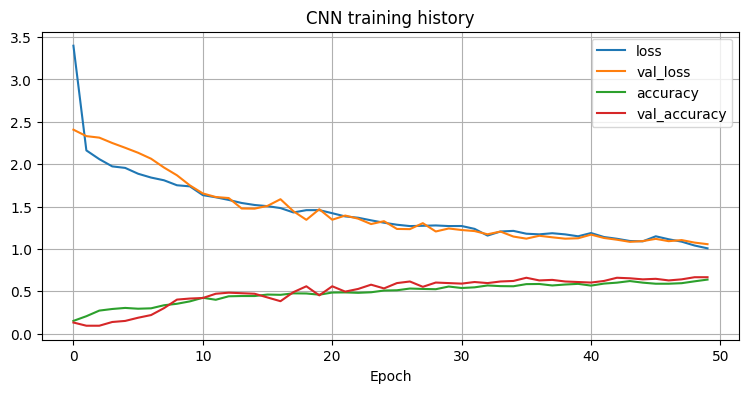

Saved artifacts: ['best_tabular_model.joblib', 'duplicate_resolution.csv', 'logmel_cnn.keras', 'model_comparison.csv', 'results.json', 'split_manifest.csv', 'test_predictions.csv']


In [13]:
error_table = pd.DataFrame({
    "track_id": test_tracks.track_id.to_numpy(),
    "true_genre": y_test,
    "tabular_prediction": tabular_test_pred,
    "cnn_prediction": cnn_test_pred,
})
display(error_table.loc[
    (error_table.true_genre != error_table.tabular_prediction) |
    (error_table.true_genre != error_table.cnn_prediction)
].head(30))

pd.DataFrame(history.history)[["loss", "val_loss", "accuracy", "val_accuracy"]].plot(
    figsize=(9, 4), title="CNN training history"
)
plt.xlabel("Epoch")
plt.grid(True)
plt.show()

results = {
    "seed": SEED,
    "original_dataset_recordings": int(len(audit)),
    "modeling_recordings_after_exact_duplicate_resolution": int(len(tracks)),
    "genre_counts": {str(k): int(v) for k, v in tracks.genre.value_counts().items()},
    "duplicate_resolution": duplicate_resolution.drop(columns=["sha256"]).to_dict(orient="records"),
    "split_counts": {k: int(len(v)) for k, v in split_frames.items()},
    "tabular_model": best_tabular_name,
    "tabular_metrics": tabular_metrics,
    "cnn_metrics": cnn_metrics,
    "comparison": comparison.to_dict(orient="records"),
    "notes": [
        "Exact byte-identical duplicate copies are reduced to one recording.",
        "Identical audio carrying conflicting genre labels is excluded from supervised modeling.",
        "The same stratified recording-level split is used for both approaches.",
        "Test set held out until final evaluation.",
        "Near-duplicates, alternate encodings and artist leakage are not ruled out.",
    ],
}
with open("artifacts/results.json", "w") as f:
    json.dump(results, f, indent=2)
comparison.to_csv("artifacts/model_comparison.csv", index=False)
error_table.to_csv("artifacts/test_predictions.csv", index=False)
duplicate_resolution.to_csv("artifacts/duplicate_resolution.csv", index=False)
print("Saved artifacts:", sorted(p.name for p in Path("artifacts").iterdir()))
